# Prompt statistics by model

In [78]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.edgecolor": "white",
    "savefig.transparent": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "xtick.labelcolor": "black",
    "ytick.labelcolor": "black",
    "legend.labelcolor": "black",
})

FAMILY_COLOR = {
    "claude": "#C47A3A",
    "gemini": "#3D6BA8",
    "gpt": "#2E8B57",
    "qwen": "#7A4E9D",
    "glm": "#C4A035",
    "kimi": "#555555",
}


def family(model: str) -> str:
    for name in FAMILY_COLOR:
        if model.startswith(name):
            return name
    return "other"


def n_special(text: str) -> int:
    return sum(not (ch.isalnum() or ch.isspace()) for ch in text)


def family_handles(with_stats: bool = False):
    handles = [
        plt.Line2D(
            [0], [0], marker="o", linestyle="none",
            markerfacecolor=color, markeredgecolor="none", markersize=7, label=name,
        )
        for name, color in FAMILY_COLOR.items()
    ]
    if with_stats:
        handles += [
            plt.Line2D(
                [0], [0], marker="o", linestyle="none",
                markerfacecolor="none", markeredgecolor="black", markersize=7, label="mean",
            ),
            plt.Line2D(
                [0], [0], marker="D", linestyle="none",
                markerfacecolor="black", markeredgecolor="black", markersize=6, label="median",
            ),
        ]
    return handles


def strip_scatter(ax, frame, column, order):
    rng = np.random.default_rng(0)
    for i, model in enumerate(order):
        y = frame.loc[frame["model"] == model, column].to_numpy()
        x = i + rng.uniform(-0.22, 0.22, size=y.size)
        ax.scatter(
            x, y, s=11, alpha=0.35, c=FAMILY_COLOR[family(model)],
            linewidths=0, zorder=2,
        )
        ax.scatter(i, np.median(y), marker="D", s=28, c="black", zorder=4)
        ax.scatter(
            i, float(y.mean()), marker="o", s=36,
            facecolors="none", edgecolors="black", linewidths=1.1, zorder=4,
        )
    ax.set_xticks(range(len(order)), order, rotation=55, ha="right", rotation_mode="anchor")
    ax.yaxis.grid(True, linestyle=":", alpha=0.7)
    ax.set_axisbelow(True)


df = pd.read_csv("train.csv")
df["char_len"] = df["text"].str.len()
df["word_len"] = df["text"].str.split().str.len()
df["n_special"] = df["text"].map(n_special)
df["special_pct"] = 100 * df["n_special"] / df["char_len"]
df["family"] = df["model"].map(family)
prompt_median = df.groupby("prompt_id")["char_len"].transform("median")
df["len_vs_prompt"] = df["char_len"] / prompt_median

assert n_special("a, b.") == 2
assert df["id"].is_unique
assert (df["char_len"] > 0).all()
assert set(df["family"]) <= set(FAMILY_COLOR)


## 1. Answers per model

Each model writes about 150 answers, one per prompt.


In [79]:
length = (
    df.groupby("model", as_index=False)
    .agg(
        answers=("id", "size"),
        mean_chars=("char_len", "mean"),
        median_chars=("char_len", "median"),
        mean_words=("word_len", "mean"),
        median_words=("word_len", "median"),
    )
    .sort_values("median_chars")
    .reset_index(drop=True)
)
for col in ("mean_chars", "median_chars", "mean_words", "median_words"):
    length[col] = length[col].round(1)
length


,model,answers,mean_chars,median_chars,mean_words,median_words
0,gemini-3.8-flash,150,706.2,583.0,100.7,84.0
1,kimi-k3,150,690.1,594.5,107.4,89.0
2,glm-5.3,150,710.3,616.5,110.3,96.0
3,qwen3.8-max,150,707.7,625.0,108.3,98.5
4,gemini-3.6-flash,150,758.6,634.5,111.2,95.5
5,gpt-5.5,150,698.6,643.5,110.3,103.5
6,claude-fable-5,149,731.0,646.0,112.5,100.0
7,gpt-5.6-terra,150,746.6,648.5,113.3,100.5
8,gpt-5.6-luna,150,766.6,673.0,115.4,104.5
9,gpt-6-astra,150,750.3,677.5,117.8,105.5


### Length scatter

Each dot is one answer. The open circle is the mean character length, the diamond is the median.

The clouds overlap. Medians only run from about 580 to about 750 characters, while single answers run from 230 to 1,900. Family does not line up with length: Gemini flashes sit at both ends.


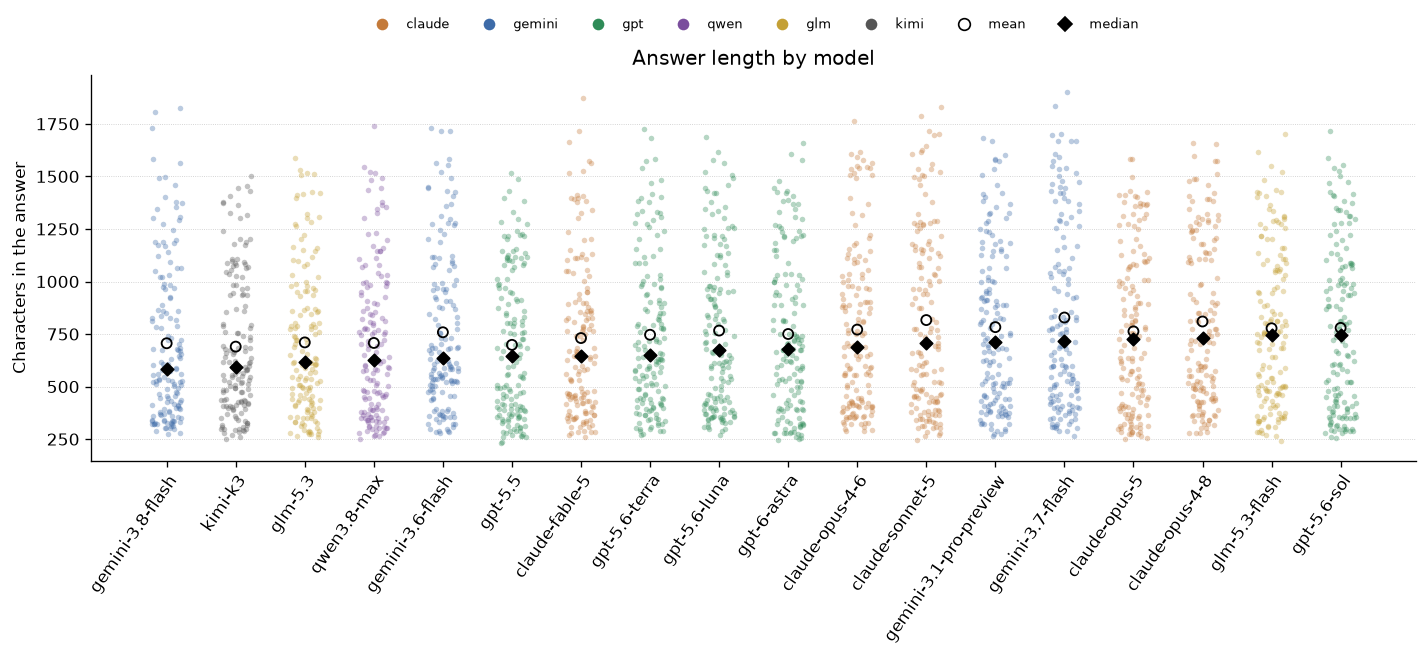

In [80]:
order = length["model"].tolist()
fig, ax = plt.subplots(figsize=(12, 5.8))
strip_scatter(ax, df, "char_len", order)
ax.set_ylabel("Characters in the answer")
ax.set_title("Answer length by model")
ax.legend(
    handles=family_handles(with_stats=True),
    frameon=False, ncol=8, loc="upper center",
    bbox_to_anchor=(0.5, 1.18), fontsize=8,
)
fig.tight_layout()


## 2. How many special characters


In [81]:
special = (
    df.groupby("model", as_index=False)
    .agg(
        mean_pct=("special_pct", "mean"),
        median_pct=("special_pct", "median"),
        mean_count=("n_special", "mean"),
    )
    .sort_values("median_pct")
    .reset_index(drop=True)
)
special["mean_pct"] = special["mean_pct"].round(2)
special["median_pct"] = special["median_pct"].round(2)
special["mean_count"] = special["mean_count"].round(1)
special


,model,mean_pct,median_pct,mean_count
0,gemini-3.7-flash,1.98,1.91,15.7
1,gemini-3.8-flash,2.07,1.99,14.1
2,gemini-3.6-flash,2.03,2.00,15.1
3,gemini-3.1-pro-preview,2.03,2.00,15.6
4,claude-opus-4-6,2.30,2.21,17.2
5,gpt-6-astra,2.46,2.40,17.9
6,claude-opus-4-8,2.62,2.51,20.0
7,claude-sonnet-5,2.74,2.59,21.0
8,gpt-5.6-luna,2.82,2.65,21.0
9,gpt-5.6-sol,2.73,2.66,20.9


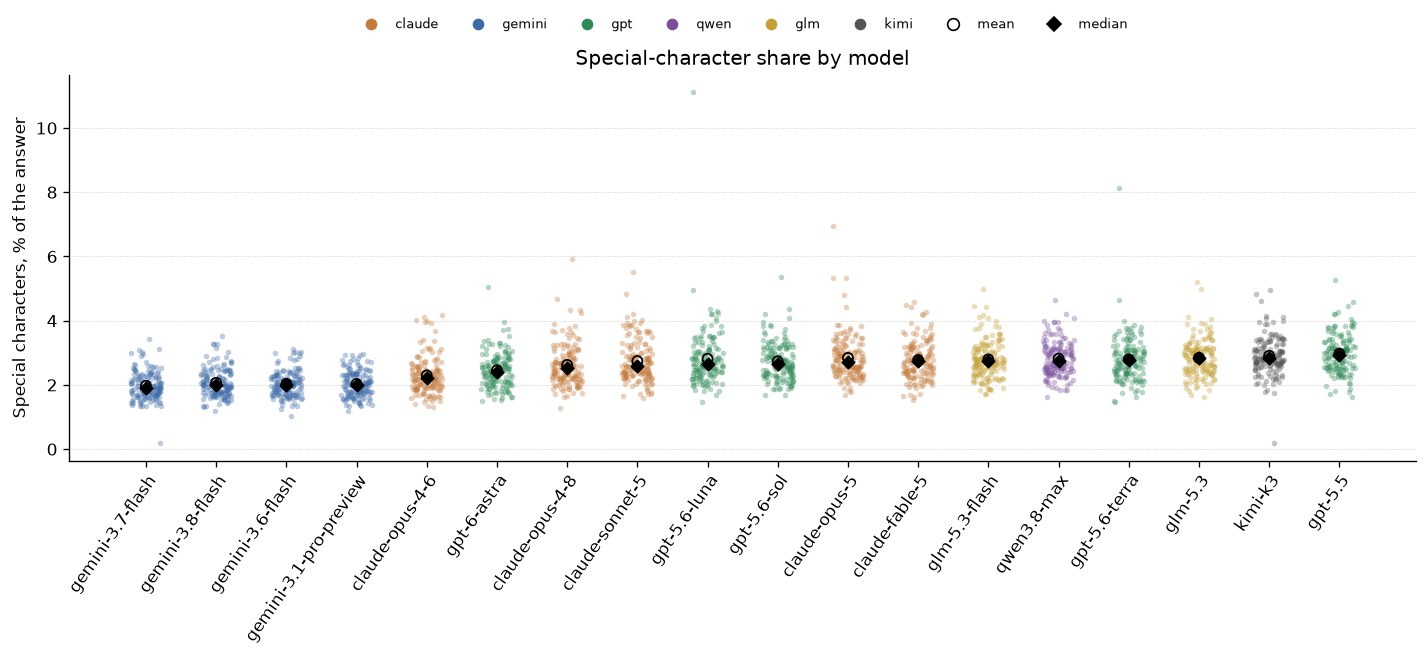

In [82]:
order = special["model"].tolist()
fig, ax = plt.subplots(figsize=(12, 5.8))
strip_scatter(ax, df, "special_pct", order)
ax.set_ylabel("Special characters, % of the answer")
ax.set_title("Special-character share by model")
ax.legend(
    handles=family_handles(with_stats=True),
    frameon=False, ncol=8, loc="upper center",
    bbox_to_anchor=(0.5, 1.18), fontsize=8,
)
fig.tight_layout()


Gemini answers use the fewest special characters, about 2.0%. `gpt-5.5` and `kimi-k3` use the most, just under 3%.
## 3. Which special characters



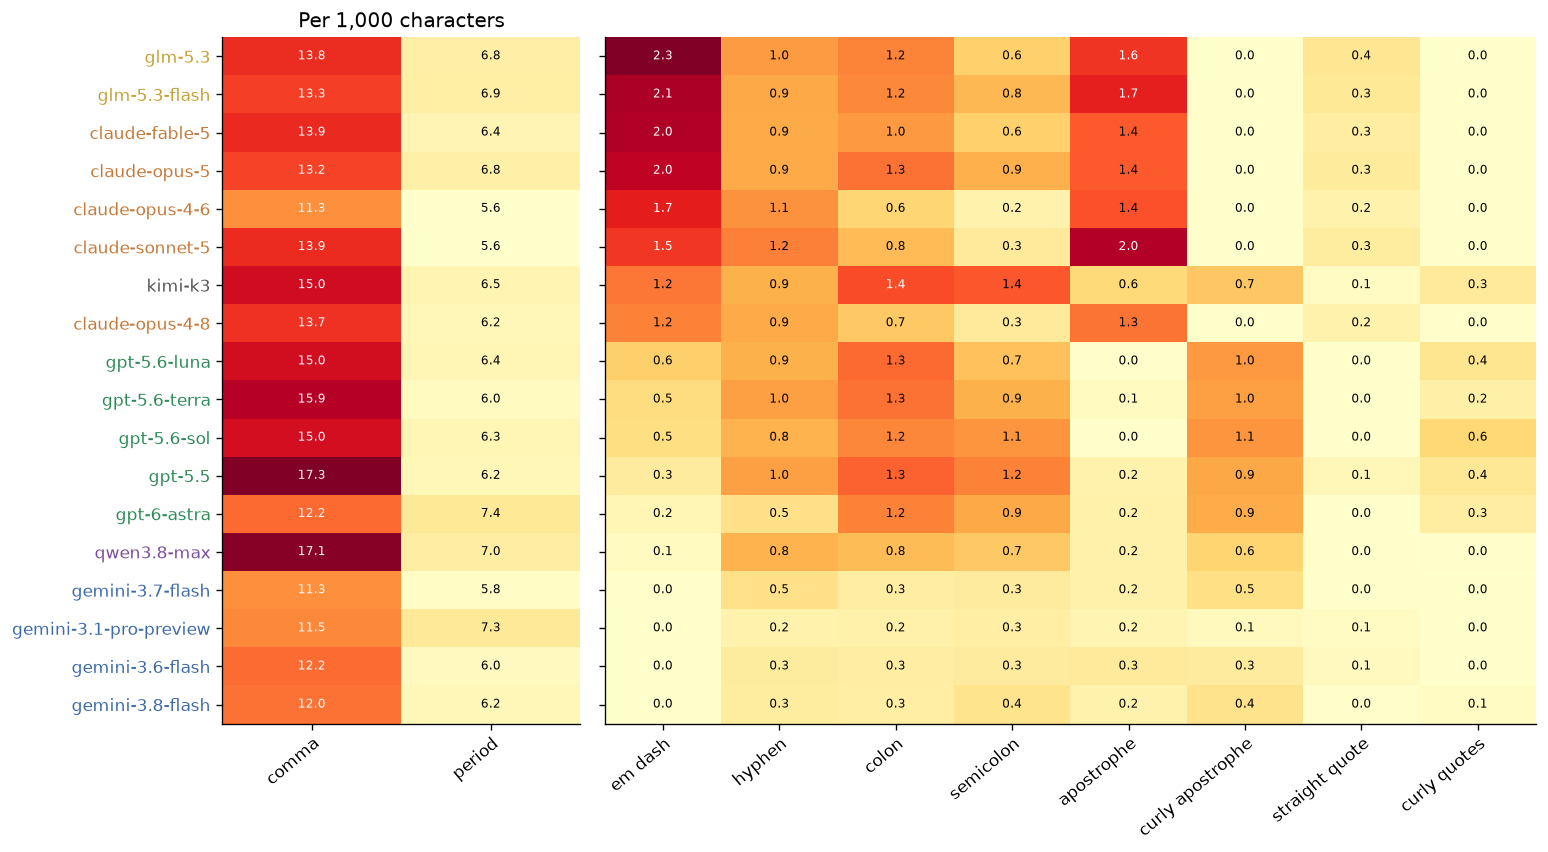

In [83]:
MARKS = [
    ("comma", ","),
    ("period", "."),
    ("em dash", "—"),
    ("hyphen", "-"),
    ("colon", ":"),
    ("semicolon", ";"),
    ("apostrophe", "'"),
    ("curly apostrophe", "’"),
    ("straight quote", '"'),
    ("curly quotes", "“”"),
]


def per_thousand(texts):
    total = 0
    counts = [0] * len(MARKS)
    for text in texts:
        total += len(text)
        for i, (_, chars) in enumerate(MARKS):
            counts[i] += sum(text.count(ch) for ch in chars)
    return [1000 * c / total for c in counts]


by_model = {
    model: per_thousand(group["text"])
    for model, group in df.groupby("model")
}
# em dash is column 2
ranked = sorted(by_model, key=lambda m: by_model[m][2], reverse=True)
matrix = np.array([by_model[m] for m in ranked])


def draw_heat(ax, values, col_labels):
    ax.imshow(values, aspect="auto", cmap="YlOrRd")
    ax.set_xticks(range(len(col_labels)), col_labels, rotation=40, ha="right", rotation_mode="anchor")
    vmax = float(values.max())
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            val = values[i, j]
            ax.text(
                j, i, f"{val:.1f}", ha="center", va="center", fontsize=7,
                color="white" if val > 0.62 * vmax else "black",
            )


fig, axes = plt.subplots(
    1, 2, figsize=(13, 7.2),
    gridspec_kw={"width_ratios": [1, 2.6]},
)
draw_heat(axes[0], matrix[:, :2], [name for name, _ in MARKS[:2]])
draw_heat(axes[1], matrix[:, 2:], [name for name, _ in MARKS[2:]])
axes[0].set_yticks(range(len(ranked)), ranked)
for tick, model in zip(axes[0].get_yticklabels(), ranked):
    tick.set_color(FAMILY_COLOR[family(model)])
axes[1].set_yticks(range(len(ranked)))
axes[1].set_yticklabels([])
axes[0].set_title("Per 1,000 characters")
fig.tight_layout()


Three habits show up:

- **Em dash.** Claude and GLM use it (about 1–2 per 1,000 characters). Gemini and Qwen almost never do. GPT sits in between and mostly low, except `gpt-5.6-luna`.
- **Apostrophe shape.** Claude and GLM use the straight apostrophe `'`. GPT models use the curly apostrophe `’`. Kimi and Qwen mix both. The same split shows up in quotation marks: curly quotes on the GPT side, straight quotes on GLM and Claude.
- **Colon and semicolon.** Gemini uses both sparingly. Everyone else uses them several times as often. Commas are the most common special character in every model, from about 11 per 1,000 characters (Gemini, `claude-opus-4-6`) to about 17 (`gpt-5.5`, `qwen3.8-max`).
